In [2]:
import pandas as pd
import geopandas as gpd
import numpy as np
from shapely.geometry import Polygon, box

In [3]:

# Load Arizona boundary
az = gpd.read_file('../data/raw/tl_2023_us_state.shp') 
az = az[az['STUSPS'] == 'AZ'].copy()

# Reproject to UTM 12N (meters)
az_utm = az.to_crs(epsg=32612)

# Get bounds
minx, miny, maxx, maxy = az_utm.total_bounds

# Create 10 km grid
cell_size = 10000  # meters
cols = np.arange(minx, maxx, cell_size)
rows = np.arange(miny, maxy, cell_size)


In [4]:
# Build grid cells as polygons
grid_cells = [
    box(x, y, x + cell_size, y + cell_size)
    for x in cols
    for y in rows
]
grid = gpd.GeoDataFrame(geometry=grid_cells, crs='EPSG:32612')

# Keep only cells that intersect Arizona
grid = gpd.clip(grid, az_utm)

# Assign cell IDs
grid['cell_id'] = range(len(grid))

print(f"Total grid cells: {len(grid)}")

Total grid cells: 3064


In [5]:
mrds = pd.read_csv('../data/raw/mrds-fUS04.txt', low_memory=False)
print(mrds.shape)
print(mrds.columns.tolist())
mrds.head()

(12951, 46)
['dep_id', 'url', 'mrds_id', 'mas_id', 'site_name', 'latitude', 'longitude', 'region', 'country', 'state', 'county', 'com_type', 'commod1', 'commod2', 'commod3', 'oper_type', 'dep_type', 'prod_size', 'dev_stat', 'ore', 'gangue', 'other_matl', 'orebody_fm', 'work_type', 'model', 'alteration', 'conc_proc', 'names', 'ore_ctrl', 'reporter', 'hrock_unit', 'hrock_type', 'arock_unit', 'arock_type', 'structure', 'tectonic', 'ref', 'yfp_ba', 'yr_fst_prd', 'ylp_ba', 'yr_lst_prd', 'dy_ba', 'disc_yr', 'prod_yrs', 'discr', 'score']


,dep_id,url,mrds_id,mas_id,site_name,latitude,longitude,region,country,state,...,ref,yfp_ba,yr_fst_prd,ylp_ba,yr_lst_prd,dy_ba,disc_yr,prod_yrs,discr,score
0,10000274,https://mrdata.usgs.gov/mrds/show-mrds.php?dep...,M002610,NaN,La Colorado Mine,33.00451,-114.16939,NaN,United States,Arizona,...,"U.S.B.M. CARD FILE.WILSON, E.D., 1951, ARIZONA...",NaN,1901.0,NaN,1949.0,NaN,NaN,NaN,NaN,B
1,10008137,https://mrdata.usgs.gov/mrds/show-mrds.php?dep...,D000070,NaN,Bridal Veil Claim,36.23334,-112.70077,NaN,United States,Arizona,...,"ALLEN, M. A. AND BUTLER, G. M. 1921, UNIV. OF ...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,D
2,10008138,https://mrdata.usgs.gov/mrds/show-mrds.php?dep...,D000074,NaN,Aurora Mine,35.40945,-114.18136,NaN,United States,Arizona,...,"DINGS, M.G., 1951 , THE WALLAPAI MINING DISTRI...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,C
3,10008139,https://mrdata.usgs.gov/mrds/show-mrds.php?dep...,D000075,NaN,Lincoln Claim,34.50005,-112.26741,NaN,United States,Arizona,...,WALDEMAR,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,D
4,10008140,https://mrdata.usgs.gov/mrds/show-mrds.php?dep...,D000078,NaN,Cochrane Property,34.00007,-112.75075,NaN,United States,Arizona,...,"FISCHER, R. P., VANADIUM FILES",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,D


In [ ]:
# Filter for copper and porphyry-related deposits
# Note: column names might vary slightly depending on MRDS version
copper = mrds[
    (mrds['commod1'].str.contains('copper', case=False, na=False)) |
    (mrds['commod2'].str.contains('copper', case=False, na=False)) |
    (mrds['commod3'].str.contains('copper', case=False, na=False))
]

# Further filter for porphyry type
porphyry = copper[
    copper['dep_type'].str.contains('porphyry', case=False, na=False)
]

# Filter to Arizona (state = 'Arizona' or lat/lon bounding box)
az_porphyry = porphyry[porphyry["state"] == 'Arizona'].copy()

# Drop rows with missing coordinates
az_porphyry = az_porphyry.dropna(subset=['latitude', 'longitude'])



In [7]:
print(f"Found {len(az_porphyry)} porphyry copper deposits in Arizona")
print(az_porphyry[['site_name', 'latitude', 'longitude', 'dep_type']].head())

# Save filtered version
az_porphyry.to_csv('../data/processed/az_porphyry_deposits.csv', index=False)

Found 52 porphyry copper deposits in Arizona
                   site_name  latitude  longitude                    dep_type
524             Chilito Mine  33.06620 -110.79791  Porphyry Cu, skarn-related
563   Sanchez Copper Deposit  32.88149 -109.53454                 Porphyry Cu
598          Squaw Peak Mine  34.48255 -111.85712              Porphyry Cu-Mo
703          Safford Deposit  32.94177 -109.60565                 Porphyry Cu
1665          Pine Flat Mine  34.36394 -112.33407              Porphyry Cu-Mo


In [8]:
# Convert deposits to UTM
deposits_utm = gpd.GeoDataFrame(
    az_porphyry,
    geometry=gpd.points_from_xy(
        az_porphyry['longitude'],
        az_porphyry['latitude']
    ),
    crs='EPSG:4326'
).to_crs(epsg=32612)

# Spatial join: which cell contains each deposit?
joined = gpd.sjoin(deposits_utm, grid, how='inner', predicate='within')

# Label cells
grid['deposit'] = 0
grid.loc[grid['cell_id'].isin(joined['cell_id']), 'deposit'] = 1

print(f"Deposit cells: {grid['deposit'].sum()}")
print(f"Non-deposit cells: {(grid['deposit'] == 0).sum()}")
print(f"Imbalance: 1 : {(grid['deposit'] == 0).sum() / grid['deposit'].sum():.1f}")

Deposit cells: 37
Non-deposit cells: 3027
Imbalance: 1 : 81.8


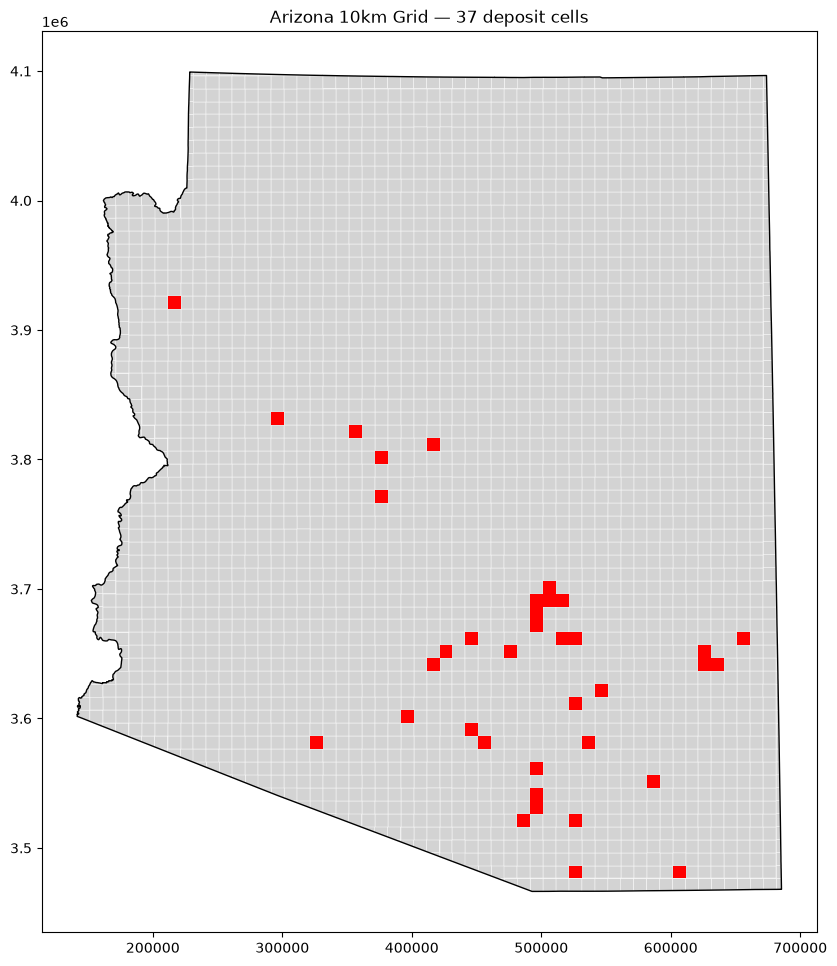

In [9]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 12))
grid.plot(ax=ax, color='lightgray', edgecolor='white', linewidth=0.3)
grid[grid['deposit'] == 1].plot(ax=ax, color='red')
az_utm.boundary.plot(ax=ax, color='black', linewidth=1)
ax.set_title(f"Arizona 10km Grid — {grid['deposit'].sum()} deposit cells")
plt.show()

In [10]:
PATH = "../data/raw/ngdbsed-fUS04/main.txt"

# Step 1: raw positions only — no header
raw = pd.read_csv(PATH, skiprows=1, header=None, dtype=str, low_memory=False)
print(raw.shape)                       # expect (16587, 32)

# Step 2: our own names, based on VERIFIED positions only
cols = ["lab_id", "field_id", "job_id", "submitter",
        "date_collect", "date_submitted", "project_name",
        "state", "country",
        "lat_wgs84", "long_wgs84", "datum_orig",
        "lat_orig", "long_orig"] + [f"extra_{i}" for i in range(raw.shape[1] - 14)]

raw.columns = cols

# Step 3: PROVE the names fit before filtering anything
print(raw["state"].value_counts().head())     # "AZ" should be on top, with thousands
print(raw["lat_wgs84"].head(3))               # should look like 33.42, 34.43, ...

(16587, 32)
state
AZ    16574
UT        8
NV        2
CA        2
NM        1
Name: count, dtype: int64
0     33.4247495
1    34.43277278
2    34.21412565
Name: lat_wgs84, dtype: str


In [11]:
samples = raw[raw["state"].str.strip() == "AZ"].copy()
samples["lat"] = pd.to_numeric(samples["lat_wgs84"])
samples["lon"] = pd.to_numeric(samples["long_wgs84"])

assert samples["lat"].between(31, 37).all(), "Latitude check failed!"
assert samples["lon"].between(-115.5, -109).all(), "Longitude check failed!"



In [12]:
# ---- get chemistry ----
best = pd.read_csv("../data/raw/ngdbsed-fUS04/bestvalue.txt", dtype=str, low_memory=False)
overlap = set(samples["lab_id"]) & set(best["lab_id"])
print("AZ samples:", samples.shape)
print("overlap with bestvalue:", len(overlap))

keep = ["CU", "MO", "AS", "PB", "ZN", "AU"]       # elements we care about
best = best[best["species"].str.upper().isin(keep)]

best["qvalue_num"] = pd.to_numeric(best["qvalue"])
best["is_censored"] = best["qvalue_num"] < 0
best["abs_value"] = best["qvalue_num"].abs()   # detection limit if censored, value if not

# Two pivots now: one for the value, one for the censored flag
wide_value = best.pivot_table(index="lab_id", columns="species", values="abs_value", aggfunc="first")
wide_censored = best.pivot_table(index="lab_id", columns="species", values="is_censored", aggfunc="first").add_suffix("_censored")

AZ samples: (16574, 34)
overlap with bestvalue: 16534


In [13]:

# ---- Glue the two notebooks together ----
geochem = samples[["lab_id", "lat", "lon"]].merge(wide_value.join(wide_censored), on="lab_id", how="inner")

print(geochem.shape)
print(geochem.head())
print("Censored fraction per element:")
print(geochem[["Cu","Mo","As","Pb","Zn","Au"]].isna().mean().round(2))

(15678, 15)
    lab_id        lat         lon    As   Au    Cu   Mo    Pb     Zn  \
0  C196144  33.424749 -114.557377   8.5  8.0  16.0  2.0  20.0  102.0   
1  C196165  34.432773 -114.292877  25.0  8.0  17.0  2.0  22.0   53.0   
2  C196374  34.214126 -114.199672   3.8  8.0  22.0  2.0  16.0   60.0   
3  C196619  34.669729 -114.382681   1.5  8.0   5.0  2.0  11.0   14.0   
4  C196667  33.580135 -114.526868   4.2  8.0  15.0  2.0  17.0   46.0   

  As_censored Au_censored Cu_censored Mo_censored Pb_censored Zn_censored  
0       False        True       False        True       False       False  
1       False        True       False        True       False       False  
2       False        True       False       False       False       False  
3       False        True       False        True       False       False  
4       False        True       False        True       False       False  
Censored fraction per element:
Cu    0.06
Mo    0.06
As    0.05
Pb    0.06
Zn    0.06
Au    0.02
dt

In [1]:
element_samples = ["Cu","Mo","As","Pb","Zn","Au"]
for el in element_samples:
    measured = geochem[el].notna.sum()
    censored = geochem[(f"{el}_censored").sum()]
    percent_censored = 100 * (f"{censored/measured}%")
    print(percent_censored)

NameError: name 'geochem' is not defined

In [14]:
# 1. Do the numbers look like Arizona?
print(geochem["lat"].min(), geochem["lat"].max())   # should be roughly 31 to 37
print(geochem["lon"].min(), geochem["lon"].max())   # should be roughly -115 to -109

31.33371057 36.99692953
-114.72578853 -109.04728525


In [15]:
# 2. How much data is censored?
print(geochem["Cu"].isna().mean())   # fraction of empty Cu values (includes censored)

0.05606582472254114


In [16]:
# 3. Do values look sane?
print(geochem["Cu"].describe())

count    14799.000000
mean        55.619840
std        362.405483
min          1.000000
25%         15.000000
50%         30.000000
75%         50.000000
max      20000.110000
Name: Cu, dtype: float64


In [17]:
geochem.to_csv('../data/processed/geochemical_values.csv', index=False)

In [18]:
import rioxarray
import matplotlib.pyplot as plt

# --- Load ---
mag_path = '../data/raw/EMAG2_V3_UpCont_DataTiff.tif'
mag = rioxarray.open_rasterio(mag_path)

# --- 2. Declare CRS (file doesn't have one, but EMAG2 is WGS84) ---
mag = mag.rio.write_crs("EPSG:4326")
print(f"CRS now: {mag.rio.crs}")
print(f"Global raster shape: {mag.shape}")           # (1, ~5000, ~10000)
print(f"Resolution: {mag.rio.resolution()} degrees")
print(f"NoData: {mag.rio.nodata}")

CRS now: EPSG:4326
Global raster shape: (1, 5399, 10800)
Resolution: (0.033333333335, -0.033333333335) degrees
NoData: -3.4028234663852886e+38


In [19]:
print("Band count:", mag.rio.count)
print("Bounds (minx, miny, maxx, maxy):", mag.rio.bounds())
print("Transform:", mag.rio.transform())
print("Coordinate names:", mag.coords)  # or mag.dims
print("Data range per band:")
for b in mag.band.values:
    band = mag.sel(band=b)
    print(f"  Band {b}: min={float(band.min()):.2f}, max={float(band.max()):.2f}, mean={float(band.mean()):.2f}")

Band count: 1
Bounds (minx, miny, maxx, maxy): (-0.0166666666675, -89.9833333378325, 359.9833333513325, 89.9833333378325)
Transform: | 0.03, 0.00,-0.02|
| 0.00,-0.03, 89.98|
| 0.00, 0.00, 1.00|
Coordinate names: Coordinates:
  * band         (band) int64 8B 1
  * y            (y) float64 43kB 89.97 89.93 89.9 89.87 ... -89.9 -89.93 -89.97
  * x            (x) float64 86kB 0.0 0.03333 0.06667 0.1 ... 359.9 359.9 360.0
    spatial_ref  int64 8B 0
Data range per band:
  Band 1: min=-340282346638528859811704183484516925440.00, max=8632.61, mean=-inf


c:\Users\HP\miniconda3\envs\arizona-porphyry\Lib\site-packages\numpy\_core\fromnumeric.py:83: RuntimeWarning: overflow encountered in reduce
  return ufunc.reduce(obj, axis, dtype, out, **passkwargs)


In [20]:
# Get AZ bounds in WGS84 (same as before)
az_wgs = az_utm.to_crs(epsg=4326)
minx, miny, maxx, maxy = az_wgs.total_bounds

minx_360 = minx + 360
maxx_360 = maxx + 360
print(f"AZ bounds (0-360):      ({minx_360:.2f}, {miny:.2f}) → ({maxx_360:.2f}, {maxy:.2f})")

# --- 5. Clip ---
mag_az = mag.rio.clip_box(minx=minx_360, miny=miny, maxx=maxx_360, maxy=maxy)
mag_az = mag_az.squeeze('band', drop=True)
print(f"Clipped shape: {mag_az.shape}")
print(f"Clipped range: {float(mag_az.min()):.1f} to {float(mag_az.max()):.1f} nT")

# Mask NoData (99999) to NaN
mag_az = mag_az.where(mag_az != mag.rio.nodata)

AZ bounds (0-360):      (245.18, 31.33) → (250.95, 37.00)
Clipped shape: (171, 174)
Clipped range: -250.5 to 562.6 nT


In [21]:
# --- Sanity check values ---
print(f"\nValue range: {float(mag_az.min()):.1f} to {float(mag_az.max()):.1f} nT")
print(f"Mean: {float(mag_az.mean()):.1f} nT")
n_nodata = int((mag_az == mag.rio.nodata).sum())
print(f"NoData pixels: {n_nodata} / {mag_az.size} ({100*n_nodata/mag_az.size:.1f}%)")


Value range: -250.5 to 562.6 nT
Mean: 33.0 nT
NoData pixels: 0 / 29754 (0.0%)


In [22]:
# --- Save clipped version for later ---
mag_az.rio.to_raster('../data/processed/mag_az.tif')
print("\nSaved clipped raster to data/processed/mag_az.tif")


Saved clipped raster to data/processed/mag_az.tif


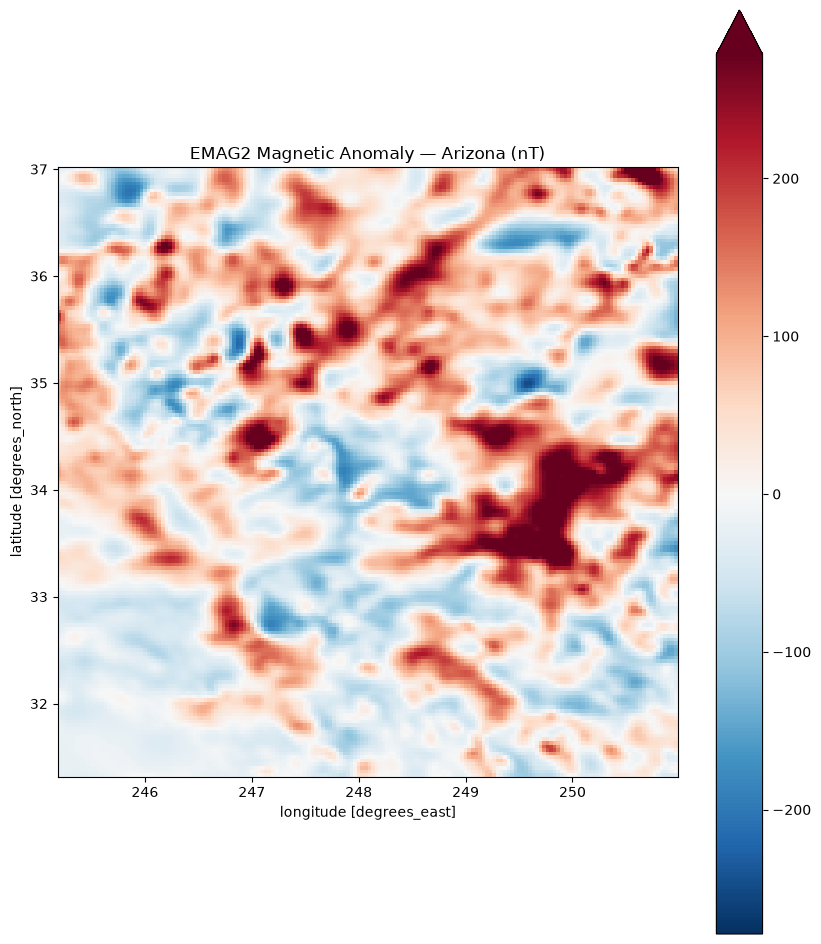

In [23]:
# --- Visualize ---
fig, ax = plt.subplots(figsize=(10, 12))
mag_az.plot(ax=ax, cmap='RdBu_r', robust=True)
ax.set_title("EMAG2 Magnetic Anomaly — Arizona (nT)")
ax.set_aspect('equal')
plt.show()

In [24]:
import geopandas as gpd

# Path pointing to the extracted shapefile
shapefile_path = '../data/raw/DI-08ver3/shapefiles/geopolys.shp'

# Load geological units
geology = gpd.read_file(shapefile_path)

In [25]:
# Display spatial dataset details
print(f"Loaded {len(geology)} geological polygons.")
print("CRS:", geology.crs)
print(geology.head())

Loaded 4851 geological polygons.
CRS: EPSG:4269
       AREA  PERIMETER  GEOLOGY_  GEOLOGY_ID  OBJECTID  DATASETID  TRACKINGID  \
0  0.015537   1.549110         2          45         1        409         122   
1  1.106111  23.187737         3          38         2        409         122   
2  0.013827   0.816593         4          46         3        409         122   
3  0.008109   0.476090         5          51         4        409         122   
4  0.008873   0.529433         6          49         5        409         122   

   TRACKINGDS  CONCEPTID  CONCEPTDS CCONF  CARTOOBJID  CARTOOBJDS  MAPUNITID  \
0          18       2406          1  None          48          21          0   
1          18       2406          1  None           2          21          0   
2          18       2406          1  None          50          21          0   
3          18       2406          1  None          48          21          0   
4          18       2406          1  None          16          21

## Phase 0 Checkpoint Answers

1. **How many porphyry Cu deposits?** — 52 in Arizona (MRDS filter)
2. **How many grid cells?** — 3,064 (10 km × 10 km, clipped to AZ)
3. **Class imbalance?** — 1 : 81.8 (37 deposit cells, 3,027 non-deposit)
4. **Coincidence of samples with cells?** — Not yet checked. 
   Geochem has 15,052 points; will spatial-join to grid in Phase 2.
5. **Deposits per cell?** — 52 deposits → 37 cells; clustering in known districts.

In [26]:
grid.to_file('../data/processed/grid_labels.geojson', driver='GeoJSON')
print(f"Saved grid with {len(grid)} cells to grid_labels.geojson")

Saved grid with 3064 cells to grid_labels.geojson
